# Actividad 3 — Segmentación de una nube de puntos 3D

Notebook de exploración, experimentos y figuras para el reporte. El código
reutilizable está en `src/`; aquí solo se llama a esas funciones y se muestran
los resultados intermedios de cada etapa.

**Pipeline**

| Etapa | Algoritmo | Atributos | Resultado |
|---|---|---|---|
| 0. Preprocesamiento | Submuestreo por vóxel + filtro estadístico | XYZ | Nube reducida |
| 1a. Orientación | K-Means (k=3) | \|normal\| | Horizontal / vertical X / vertical Y |
| 1b-c. Superficies | DBSCAN | XYZ (puntos horizontales) | Piso, techo, plataformas |
| 2a. Columnas | Cobertura vertical + DBSCAN 2D | XY | Columnas |
| 2b. Materiales | K-Means (k=5) | Color (tono, saturación, brillo) | Claro, verde, óxido, oscuro |
| 2c-d. Objetos | DBSCAN por material + reglas | XYZ, material, altura | Tubería, viga, maquinaria |
| 2e. Suavizado | Voto mayoritario k-NN | XYZ | Etiquetas limpias |
| 4. Transferencia | Vecino más cercano | XYZ | Nube original etiquetada |

Ejecutar desde la carpeta `notebooks/` con el entorno del proyecto.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import clustering as C
from src.evaluation import kmeans_sweep
from src.pipeline import DEFAULT_INPUT, prepare_data
from src.preprocessing import load_point_cloud, remove_outliers, to_arrays, voxel_downsample
from src.visualization import (CLASS_COLORS, colors_from_classes, colors_from_segments,
                               plot_legend, plot_projections, render_view)

FIG = ROOT / "results/figures"
MET = ROOT / "results/metricas"
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.float_format", "{:.3f}".format)
%matplotlib inline

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


## 1. Exploración de los datos

La nube original tiene posición (XYZ), color (RGB) y normal por punto.
El eje Z es vertical.

In [2]:
full = to_arrays(load_point_cloud(DEFAULT_INPUT))
print(f"Puntos: {len(full):,}")
pd.DataFrame({"min": full.points.min(0), "max": full.points.max(0),
              "rango": np.ptp(full.points, 0)}, index=["x", "y", "z"]).round(2)

Puntos: 1,647,021


,min,max,rango
x,-2.580,28.800,31.390
y,-11.870,22.990,34.870
z,-2.310,14.460,16.770


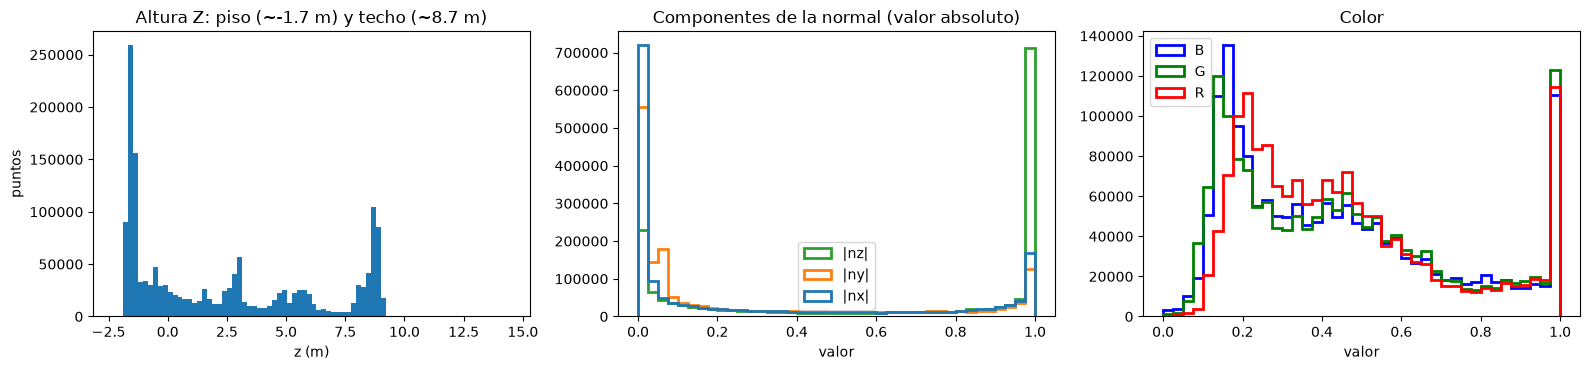

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
axes[0].hist(full.points[:, 2], bins=80, color="tab:blue")
axes[0].set(title="Altura Z: piso (~-1.7 m) y techo (~8.7 m)", xlabel="z (m)", ylabel="puntos")
axes[1].hist(np.abs(full.normals), bins=40, label=["|nx|", "|ny|", "|nz|"], histtype="step", lw=2)
axes[1].set(title="Componentes de la normal (valor absoluto)", xlabel="valor")
axes[1].legend()
axes[2].hist(full.colors, bins=40, color=["r", "g", "b"], histtype="step", lw=2, label=["R", "G", "B"])
axes[2].set(title="Color", xlabel="valor")
axes[2].legend()
fig.tight_layout()
fig.savefig(FIG / "10_exploracion_histogramas.png", dpi=120)

Las normales se concentran en valores cercanos a 0 y 1: la escena está dominada
por superficies alineadas con los ejes (piso, techo, caras de columnas y vigas).
Esto justifica una primera etapa que agrupe por orientación.

## 2. Preprocesamiento: tamaño de vóxel

El submuestreo reduce el costo de DBSCAN y homogeneiza la densidad (el escáner
genera más puntos cerca de su posición). Se comparan varios tamaños de vóxel.

In [4]:
pcd = load_point_cloud(DEFAULT_INPUT)
rows = []
for v in (0.04, 0.06, 0.08, 0.10, 0.15):
    t = time.time()
    d = voxel_downsample(pcd, v)
    d, _ = remove_outliers(d)
    rows.append({"voxel (m)": v, "puntos": len(d.points), "% del original": len(d.points) / len(full),
                 "tiempo (s)": time.time() - t})
pd.DataFrame(rows)

,voxel (m),puntos,% del original,tiempo (s)
0,0.040,1375550,0.835,2.802
1,0.060,763508,0.464,1.599
2,0.080,454898,0.276,1.017
3,0.100,300659,0.183,0.758
4,0.150,140428,0.085,0.435


Se eligió **0.08 m**: conserva tuberías y perfiles delgados (~10-15 cm) con al
menos 2 puntos de ancho y deja ~455 mil puntos, suficiente para que DBSCAN corra
en segundos.

Cargando data/raw/FARO_Scan_Full_Sub1_down3_with_normals.ply


  puntos originales: 1,647,021
  tras vóxel 0.08 m y filtro de outliers: 454,898


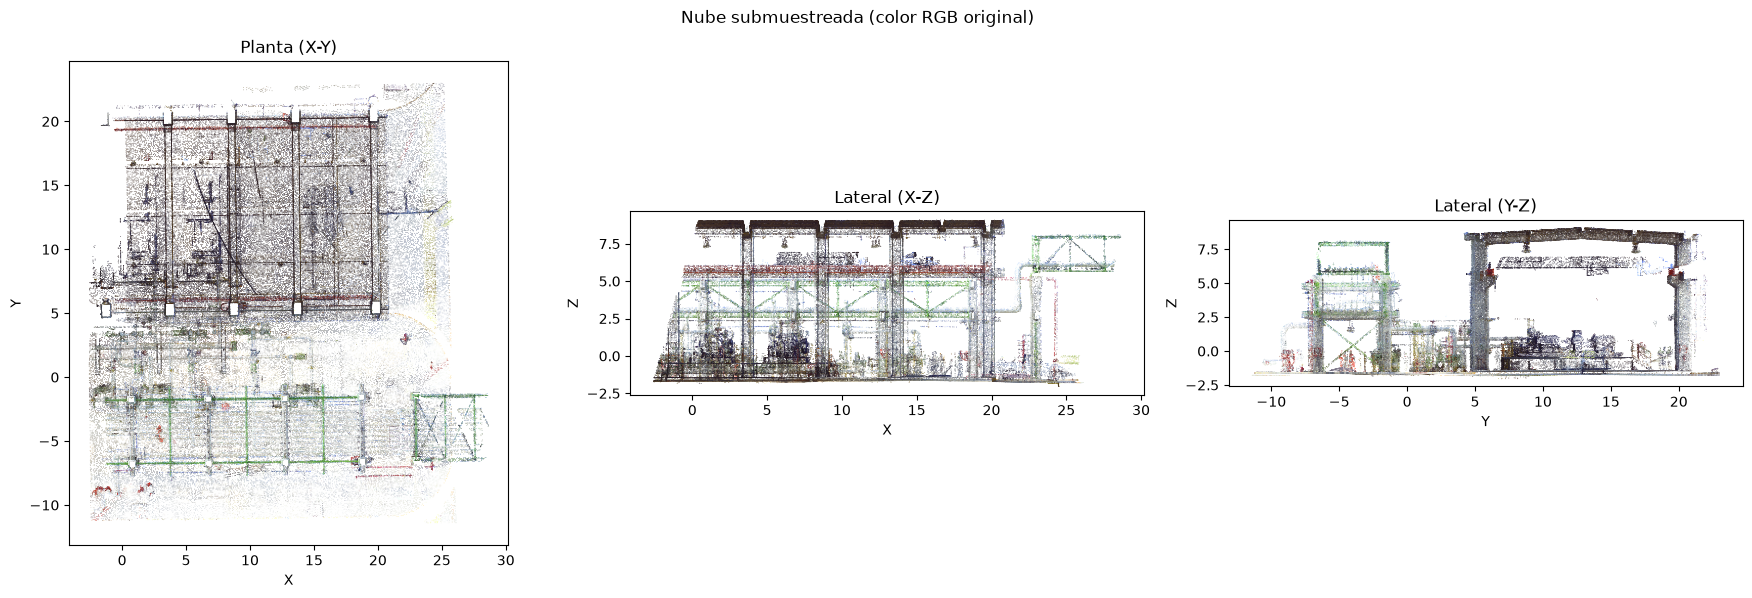

In [5]:
data = prepare_data()
plot_projections(data.points, data.colors, title="Nube submuestreada (color RGB original)");

## 3. Etapa 1a — Orientación con K-Means sobre |normal|

Se usa el valor absoluto porque `n` y `-n` describen la misma superficie.
Selección de k con inercia (codo), silhouette (↑) y Davies-Bouldin (↓):

In [6]:
sweep_orient = pd.read_csv(MET / "kmeans_orientacion.csv")
sweep_orient

,k,inercia,silhouette,davies_bouldin
0,2,82792.682,0.608,0.726
1,3,31874.750,0.695,0.526
2,4,24577.340,0.648,0.637
3,5,18180.527,0.655,0.630
4,6,12842.423,0.656,0.601


Centroides [H, VX, VY]:
 [[0.08 0.09 0.97]
 [0.91 0.2  0.17]
 [0.19 0.9  0.22]]


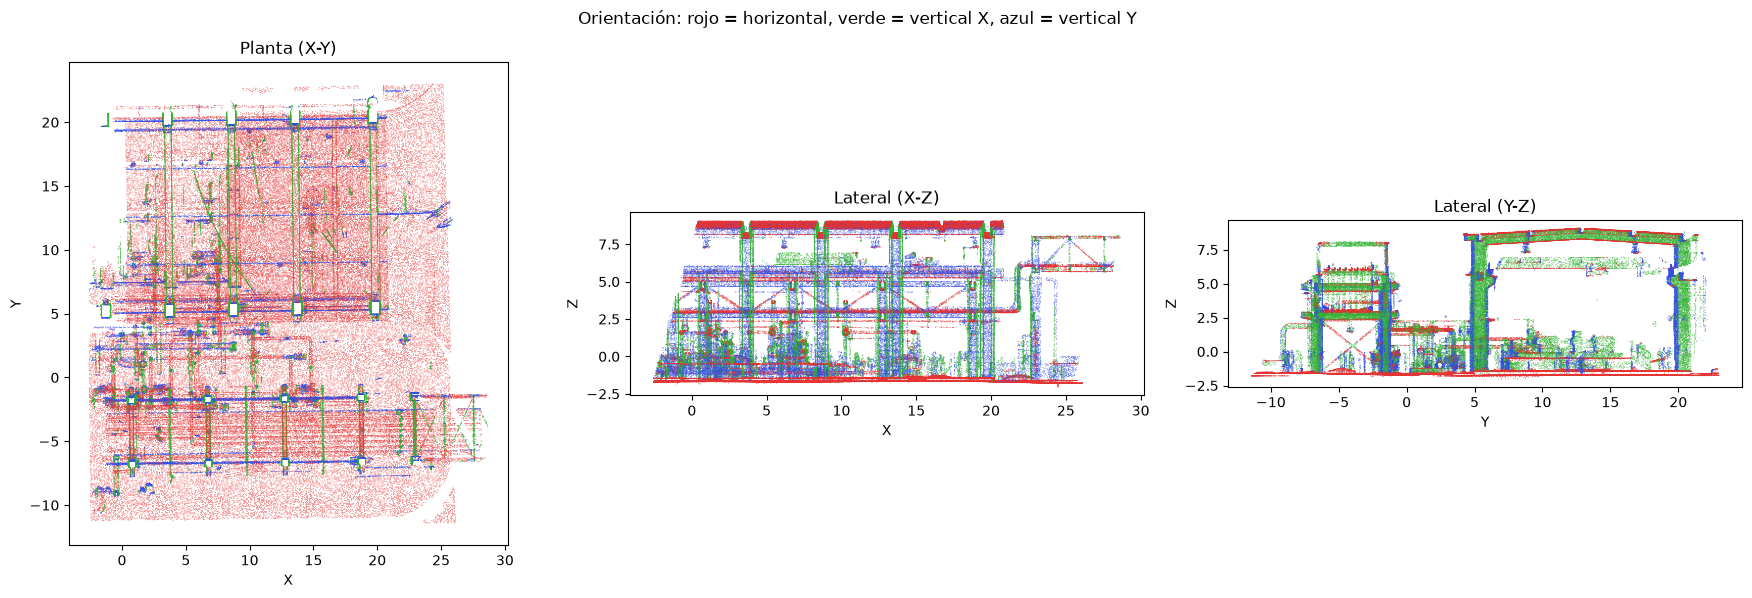

In [7]:
s1 = C.stage1_structure(data)
print("Centroides [H, VX, VY]:\n", s1["centers"].round(2))
orient_rgb = np.array([(0.9, 0.2, 0.2), (0.2, 0.7, 0.2), (0.2, 0.3, 0.9)])
plot_projections(data.points, orient_rgb[s1["orientation"]],
                 title="Orientación: rojo = horizontal, verde = vertical X, azul = vertical Y");

k=3 maximiza silhouette (0.695) y minimiza Davies-Bouldin (0.526); cada
centroide tiene una componente dominante ≈ 0.9-0.97, es decir, los tres grupos
corresponden a las tres orientaciones de los ejes.

## 4. Etapa 1b-c — Superficies horizontales con DBSCAN

Agrupar solo por altura no funciona: el piso no es perfectamente plano
(desnivel ~10 cm) y hay superficies a distintas alturas. DBSCAN sobre XYZ separa
superficies **conexas**, que luego se etiquetan por altura y tamaño.
Experimento con `eps`:

In [8]:
horiz = s1["orientation"] == C.HORIZONTAL
rows = []
for eps in (0.10, 0.15, 0.20, 0.25):
    import warnings
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        lab = C.cluster_surfaces(data.points[horiz], eps=eps)
    stats = C.describe_segments(data.points[horiz], lab)
    rows.append({"eps (m)": eps, "superficies": len(stats), "% ruido": (lab < 0).mean(),
                 "mayor superficie (pts)": stats[0]["n"] if stats else 0})
pd.DataFrame(rows)

,eps (m),superficies,% ruido,mayor superficie (pts)
0,0.100,2949,0.707,970
1,0.150,611,0.013,122615
2,0.200,433,0.005,123102
3,0.250,383,0.003,124250


Con `eps = 0.10` (≈ separación entre puntos tras el vóxel de 0.08 m) el 71 % de
los puntos queda como ruido y el piso se fragmenta. A partir de 0.15 los
resultados son estables; se usa **0.15 m**.

sin_clasificar    207,478
piso              126,739
techo              54,259
plataforma         27,475
horizontal_otro    38,947


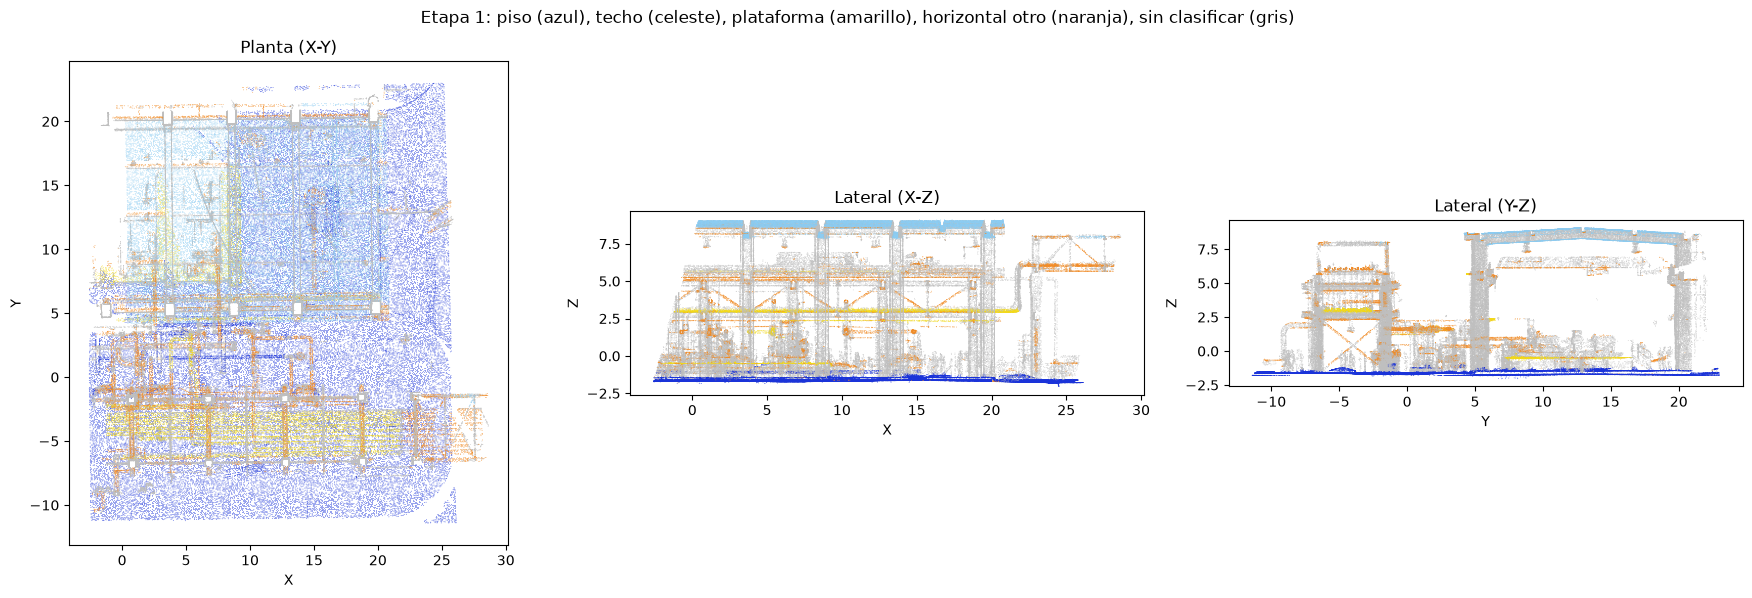

In [9]:
for c, n in zip(*np.unique(s1["classes"], return_counts=True)):
    print(f"{C.CLASS_NAMES[c]:<16} {n:>8,}")
plot_projections(data.points, colors_from_classes(s1["classes"]),
                 title="Etapa 1: piso (azul), techo (celeste), plataforma (amarillo), "
                       "horizontal otro (naranja), sin clasificar (gris)");

## 5. Etapa 2a — Columnas

DBSCAN directamente sobre el resto de puntos no separa objetos: columnas,
vigas y tuberías se tocan y forman dos componentes gigantes. Las columnas son
las que conectan todo, por eso se detectan primero: en planta, una columna es
una celda que tiene puntos en casi toda la altura.

Puntos en columnas: 75,159 de 246,425


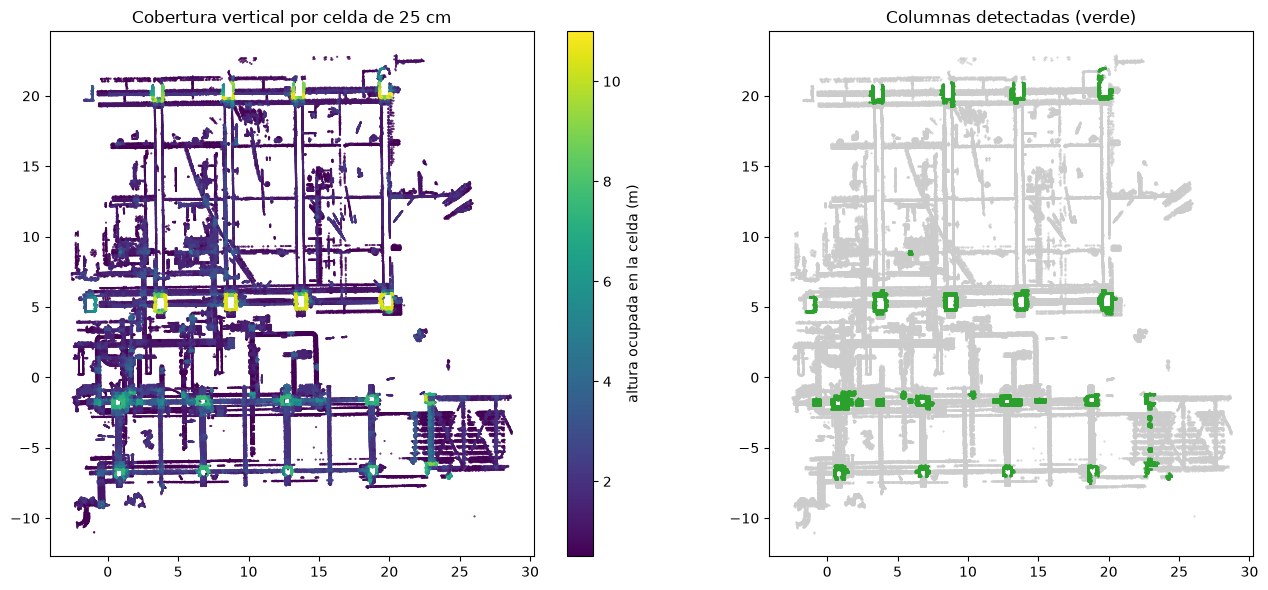

In [10]:
floor_z = float(np.median(data.points[s1["classes"] == C.FLOOR, 2]))
todo = np.flatnonzero(np.isin(s1["classes"], [C.UNLABELED, C.HORIZONTAL_OTHER]))
rest = data.subset(todo)
coverage = C.vertical_coverage(rest.points, floor_z)
is_column = C.detect_columns(rest.points, floor_z)
print(f"Puntos en columnas: {is_column.sum():,} de {len(rest):,}")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sc = axes[0].scatter(rest.points[:, 0], rest.points[:, 1], c=coverage, s=0.2, cmap="viridis")
fig.colorbar(sc, ax=axes[0], label="altura ocupada en la celda (m)")
axes[0].set(title="Cobertura vertical por celda de 25 cm", aspect="equal")
axes[1].scatter(rest.points[~is_column, 0], rest.points[~is_column, 1], s=0.2, c="0.8")
axes[1].scatter(rest.points[is_column, 0], rest.points[is_column, 1], s=0.5, c="tab:green")
axes[1].set(title="Columnas detectadas (verde)", aspect="equal")
fig.tight_layout()
fig.savefig(FIG / "11_columnas.png", dpi=120)

In [11]:
# Efecto de quitar columnas: DBSCAN sobre el resto
from sklearn.cluster import DBSCAN
for name, pts in [("con columnas", rest.points), ("sin columnas", rest.points[~is_column])]:
    lab = DBSCAN(eps=0.2, min_samples=10, n_jobs=-1).fit_predict(pts)
    sizes = np.bincount(lab[lab >= 0])
    print(f"{name}: {len(sizes)} objetos, el mayor tiene {sizes.max() / len(pts):.0%} de los puntos")

con columnas: 190 objetos, el mayor tiene 91% de los puntos


sin columnas: 318 objetos, el mayor tiene 49% de los puntos


## 6. Etapa 2b — Materiales con K-Means sobre color

Aun sin columnas queda un componente grande (estructura abierta + tuberías +
máquinas). Los colores originales distinguen materiales: tuberías claras,
estructura verde, rieles color óxido, máquinas oscuras. Se usa el tono en el
círculo cromático (cos, sin) ponderado por la saturación, más el brillo.

,k,inercia,silhouette,davies_bouldin
0,2,21081.359,0.330,1.254
1,3,14717.545,0.349,0.960
2,4,11315.685,0.344,1.029
3,5,9421.762,0.354,1.002
4,6,7801.045,0.350,0.962
5,7,6814.607,0.360,0.928
6,8,6009.893,0.360,0.921


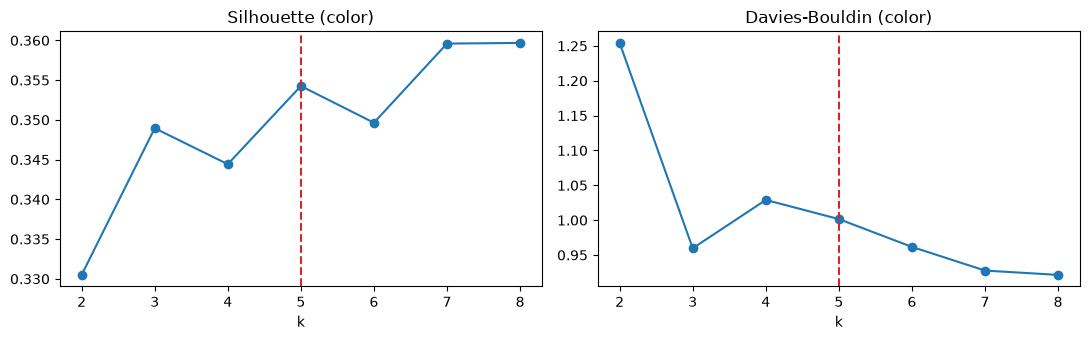

In [12]:
sweep_color = pd.read_csv(MET / "kmeans_color.csv")
display(sweep_color)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(sweep_color["k"], sweep_color["silhouette"], "o-")
axes[0].set(title="Silhouette (color)", xlabel="k")
axes[1].plot(sweep_color["k"], sweep_color["davies_bouldin"], "o-")
axes[1].set(title="Davies-Bouldin (color)", xlabel="k")
for ax in axes:
    ax.axvline(5, color="tab:red", ls="--")
fig.tight_layout()

A diferencia de la orientación, las métricas de color no muestran un óptimo
claro (silhouette ≈ 0.33-0.36 para todo k): los colores no forman grupos bien
separados. Se eligió **k=5** porque cada cluster corresponde a un material
interpretable (ver tabla siguiente), no por las métricas. Es el punto más débil
del método.

In [13]:
s2 = C.stage2_objects(data, s1)
pd.DataFrame([{"RGB medio": np.round(rgb, 2), "material": C.MATERIAL_NAMES[m]}
              for rgb, m in s2["colors"]])

,RGB medio,material
0,"[0.19, 0.18, 0.26]",oscuro
1,"[0.29, 0.25, 0.25]",oscuro
2,"[0.39, 0.53, 0.32]",verde
3,"[0.69, 0.73, 0.75]",claro
4,"[0.42, 0.23, 0.17]",oxido


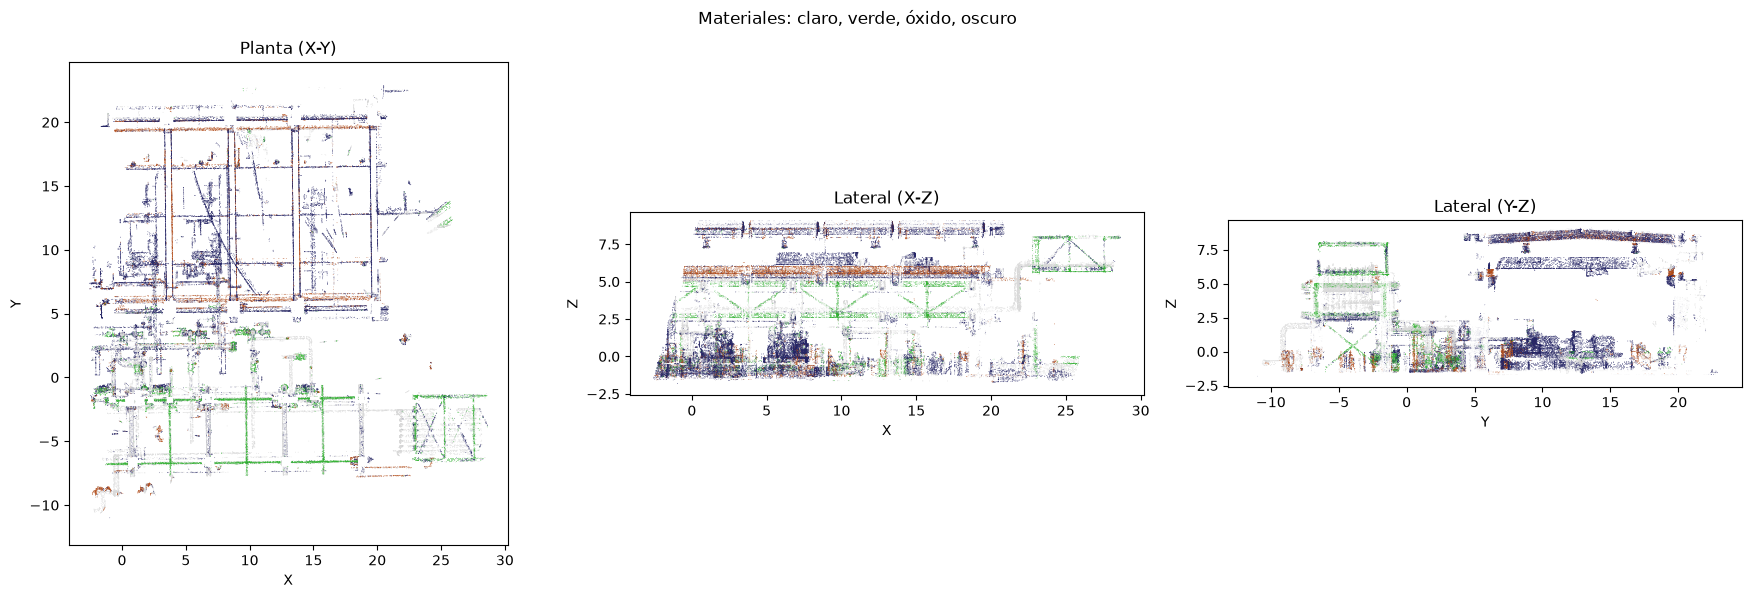

In [14]:
mat_rgb = np.array([(0.85, 0.85, 0.85), (0.2, 0.7, 0.2), (0.7, 0.3, 0.1), (0.15, 0.15, 0.4)])
mat_colors = np.where(s2["materials"][:, None] >= 0, mat_rgb[np.maximum(s2["materials"], 0)], 1.0)
plot_projections(data.points, mat_colors, title="Materiales: claro, verde, óxido, oscuro");

## 7. Etapa 2c-e — Objetos, clases y suavizado

DBSCAN (`eps = 0.2 m`) dentro de cada material separa objetos; cada objeto
recibe una clase según su material y su altura sobre el piso:

- material claro → **tubería**
- elevado (base a más de 3 m) o verde → **viga / estructura metálica**
- oscuro con mediana de altura < 2.5 m → **maquinaria**
- resto → **otros**

Finalmente cada punto toma la clase mayoritaria de sus 10 vecinos.

Objetos DBSCAN: 1098


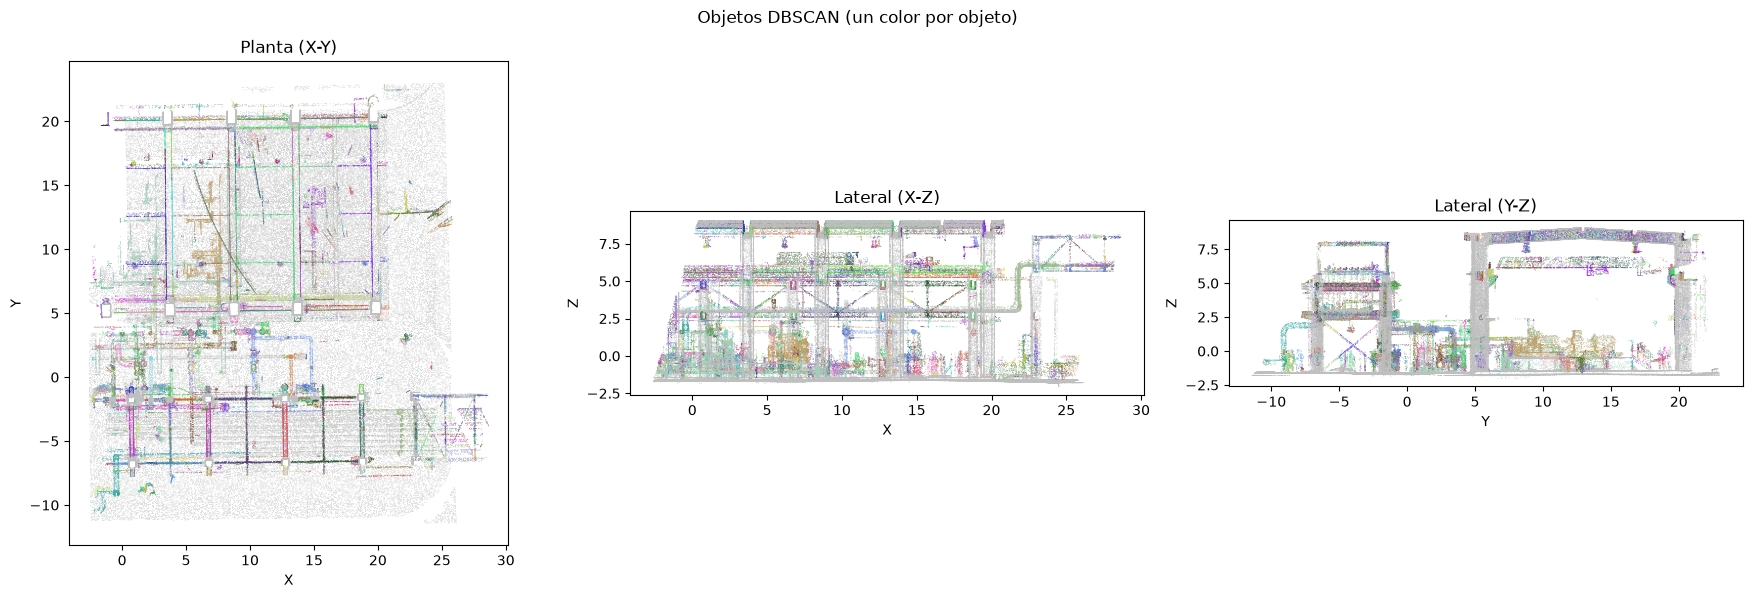

In [15]:
print(f"Objetos DBSCAN: {s2['objects'].max() + 1}")
plot_projections(data.points, colors_from_segments(s2["objects"]),
                 title="Objetos DBSCAN (un color por objeto)");

,puntos (nube submuestreada)
piso,126739
columna,76875
viga_estructura,73527
techo,54259
tuberia,50468
maquinaria,44189
plataforma,27475
otros,1366


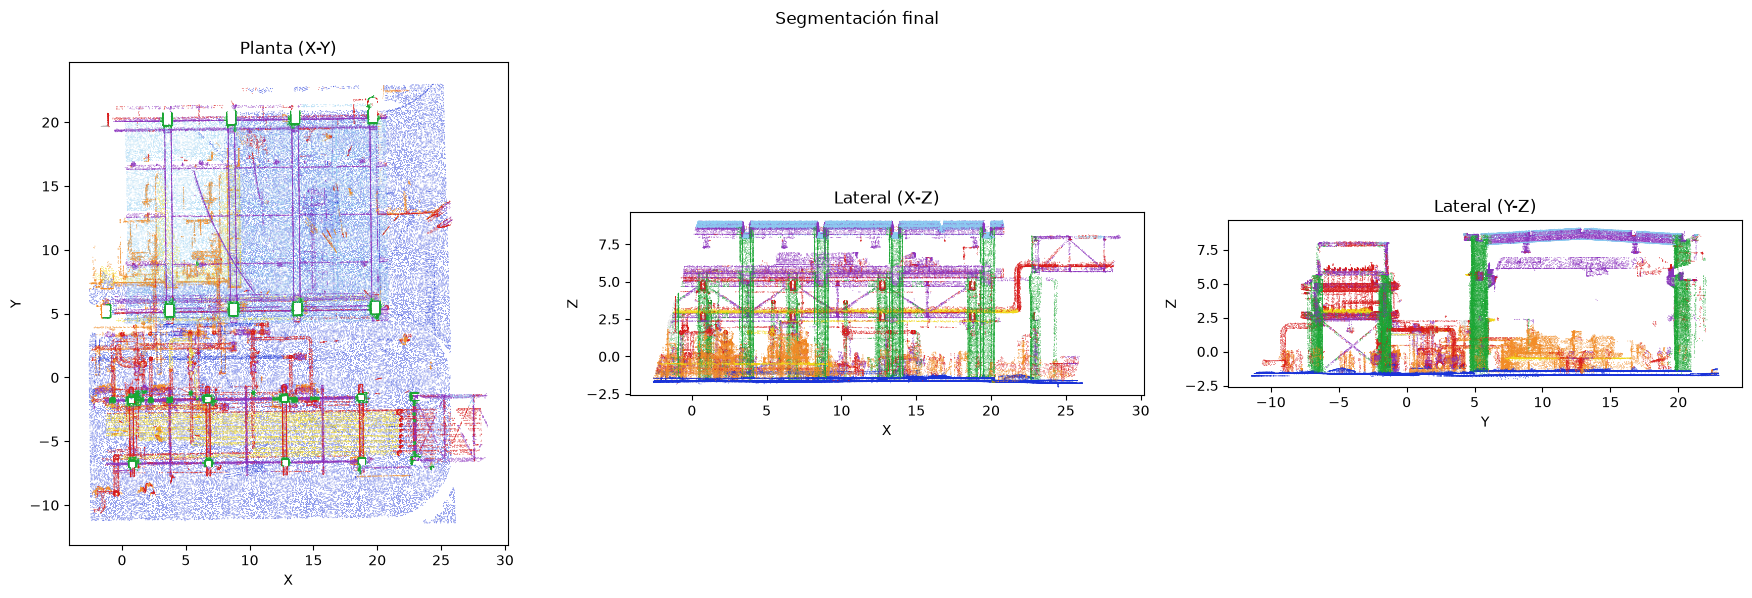

In [16]:
counts = pd.Series(s2["classes"]).map(C.CLASS_NAMES).value_counts()
display(counts.to_frame("puntos (nube submuestreada)"))
plot_projections(data.points, colors_from_classes(s2["classes"]), title="Segmentación final");

## 8. Estabilidad frente a semillas y parámetros

Calculado con `python -m src.evaluation` (≈ 2 min). Concordancia = fracción de
puntos con la misma clase que la configuración por defecto.

In [17]:
pd.read_csv(MET / "estabilidad.csv")

,variante,concordancia,ARI,piso,techo,plataforma,columna,tuberia,viga_estructura,maquinaria,otros
0,semilla 1,0.998,0.997,1.000,1.000,1.000,1.000,0.999,0.993,0.998,0.884
1,semilla 2,0.999,0.999,1.000,1.000,1.000,1.000,0.998,1.000,1.000,0.902
2,semilla 3,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
3,semilla 4,0.999,0.998,1.000,1.000,1.000,1.000,0.998,0.995,0.999,0.884
4,eps superficies 0.10,0.506,0.405,0.129,0.016,0.000,0.996,0.582,0.860,0.979,0.474
5,eps superficies 0.20,0.983,0.975,1.000,1.000,1.000,0.993,0.908,0.978,0.981,0.977
6,eps objetos 0.15,0.981,0.971,1.000,1.000,1.000,0.999,0.908,0.983,0.948,0.691
7,eps objetos 0.25,0.993,0.989,1.000,1.000,1.000,1.000,0.987,0.976,0.989,0.825
8,k color 4,0.957,0.927,1.000,1.000,1.000,0.999,0.812,0.991,0.802,0.645
9,k color 6,0.939,0.915,1.000,1.000,1.000,0.999,0.555,0.940,0.999,0.556


- Las etapas geométricas (piso, techo, plataforma, columna) son muy estables.
- El cambio de semilla ya no altera el resultado (≥ 99.8 %) tras usar 30
  inicializaciones en el K-Means de color.
- Lo más sensible es el número de clusters de color: con k=6 solo el 55 % de
  las tuberías conserva su clase.

## 9. Nube original completa

Cada punto original toma la clase del centroide de vóxel más cercano; los puntos
a más de 0.16 m (outliers filtrados) quedan como "otros".

In [18]:
full_classes, dist = C.transfer_labels(full.points, data.points, s2["classes"], max_dist=0.16)
print(f"Distancia al vecino: mediana {np.median(dist) * 100:.1f} cm, "
      f"p99 {np.percentile(dist, 99) * 100:.1f} cm; {int((dist > 0.16).sum()):,} puntos lejanos")
pd.read_csv(MET / "conteo_clases_nube_completa.csv")

Distancia al vecino: mediana 3.0 cm, p99 5.3 cm; 8,123 puntos lejanos


,clase,puntos,porcentaje
0,piso,493411,0.300
1,techo,208994,0.127
2,plataforma,87446,0.053
3,columna,283708,0.172
4,tuberia,161992,0.098
5,viga_estructura,258708,0.157
6,maquinaria,140026,0.085
7,otros,12736,0.008


## 10. Capturas 3D para el reporte

Vistas renderizadas con Open3D sobre la nube completa. Para la vista interior y
la planta se ocultan los puntos sobre 7 m (techo) para ver el interior.

aerea


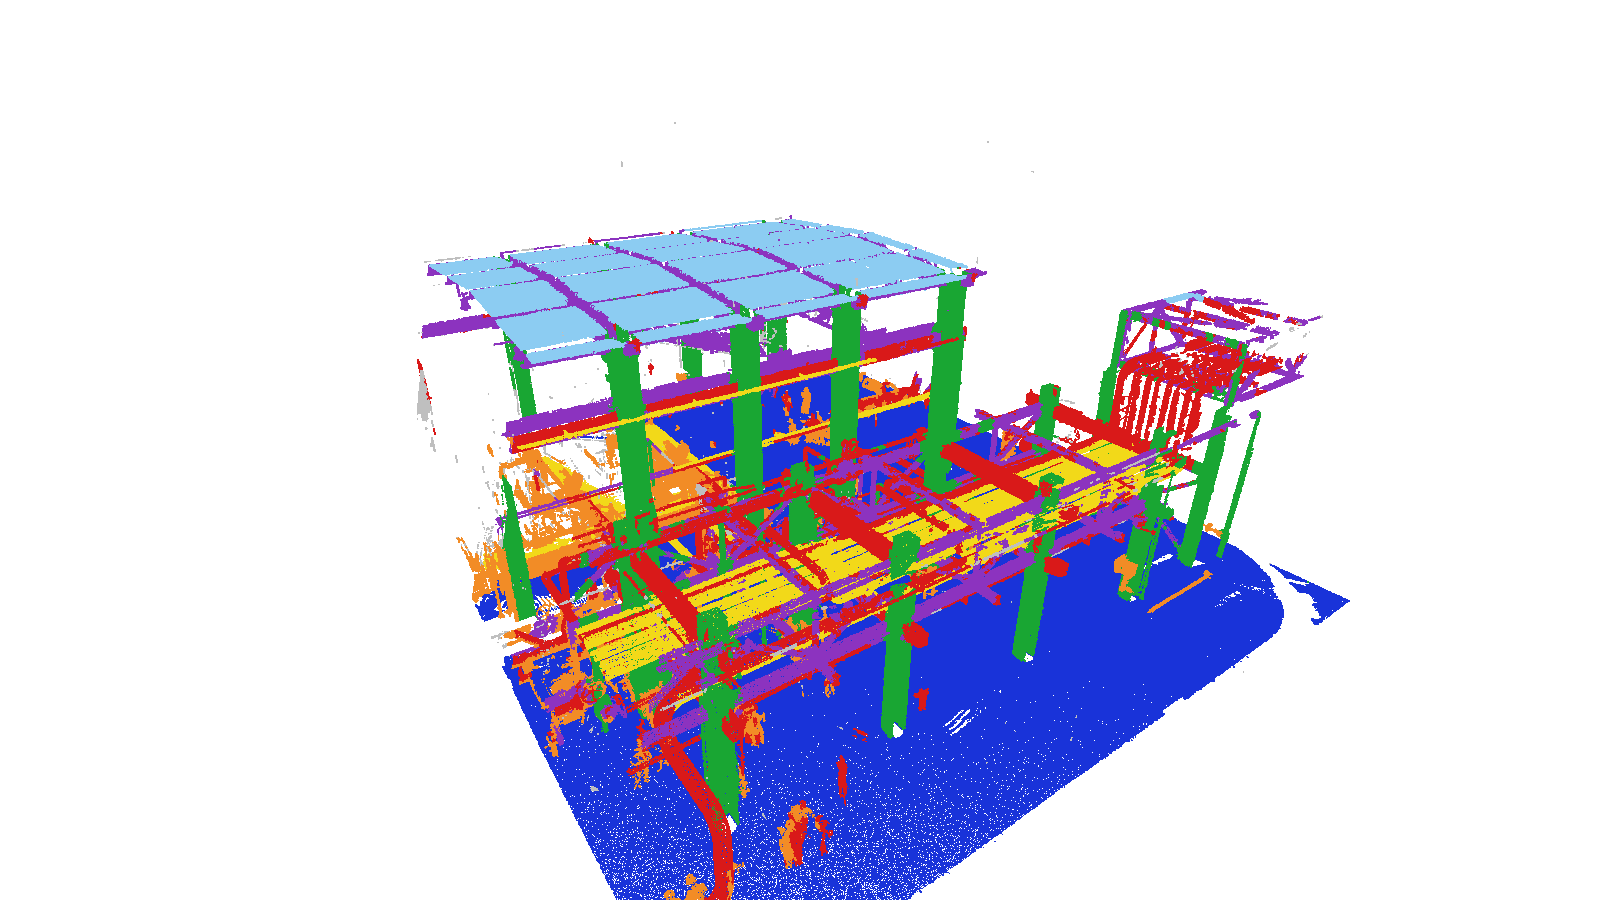

aerea_opuesta


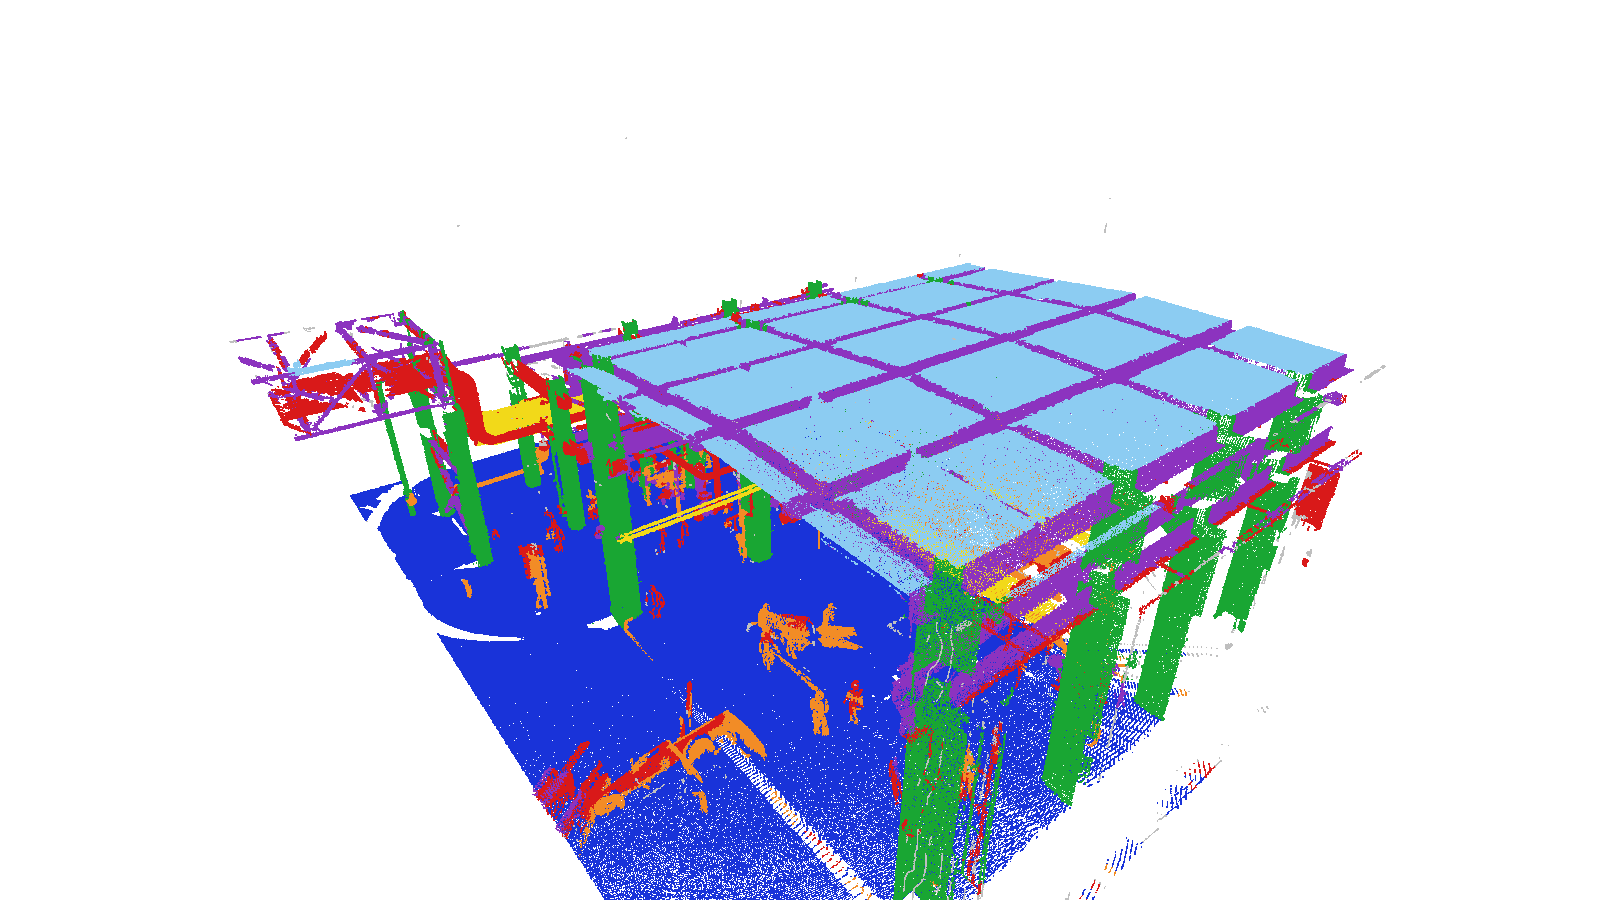

lateral


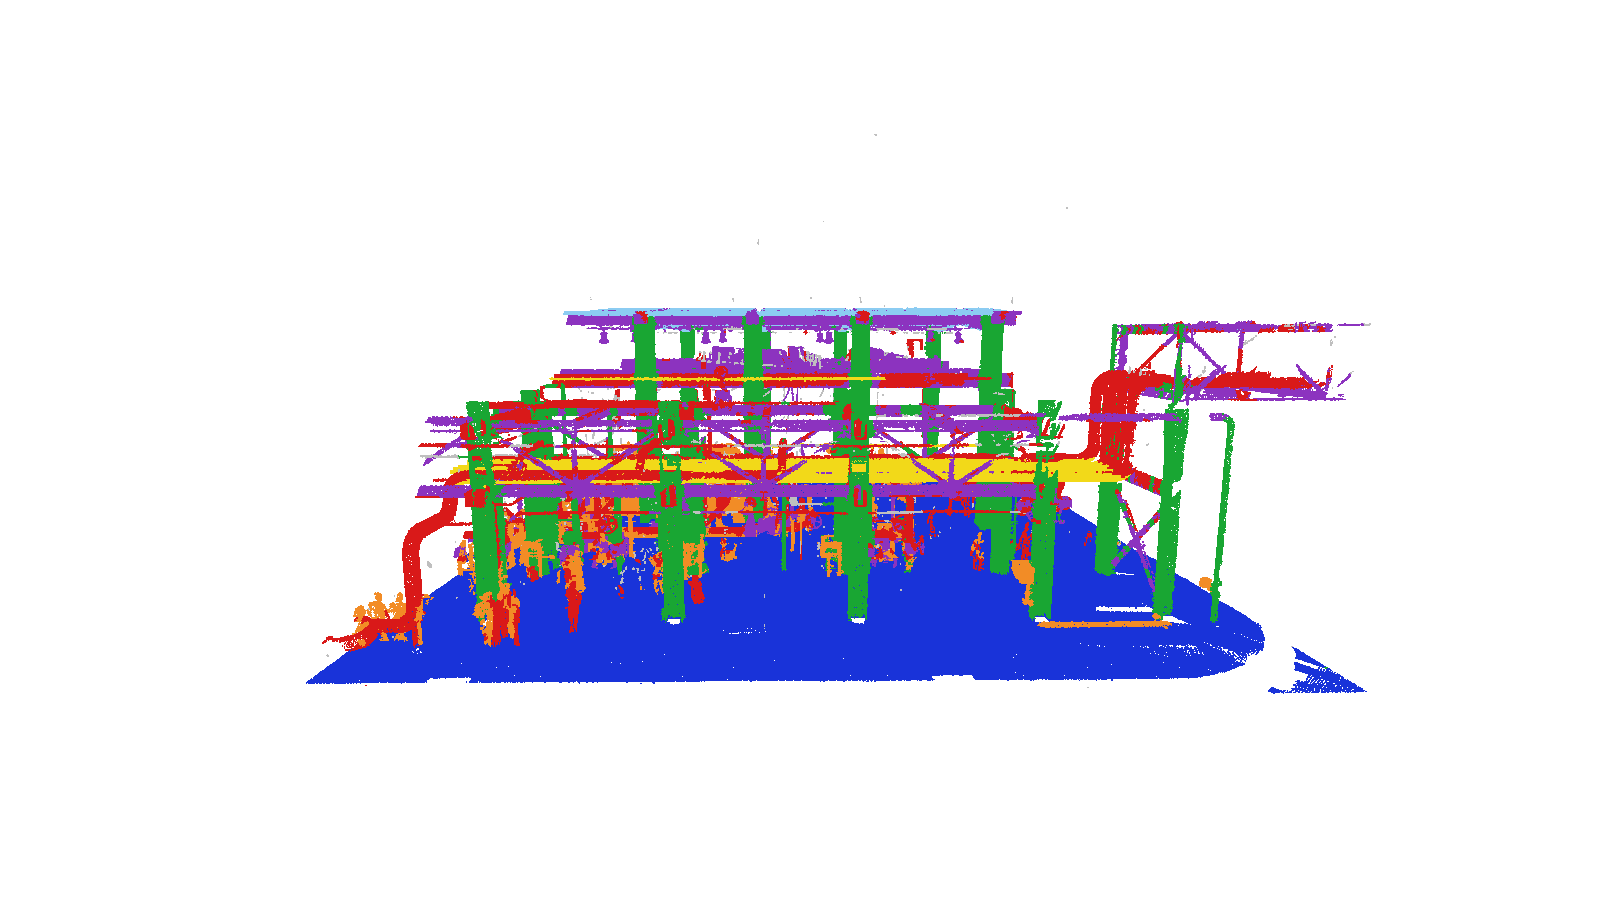

interior_nave


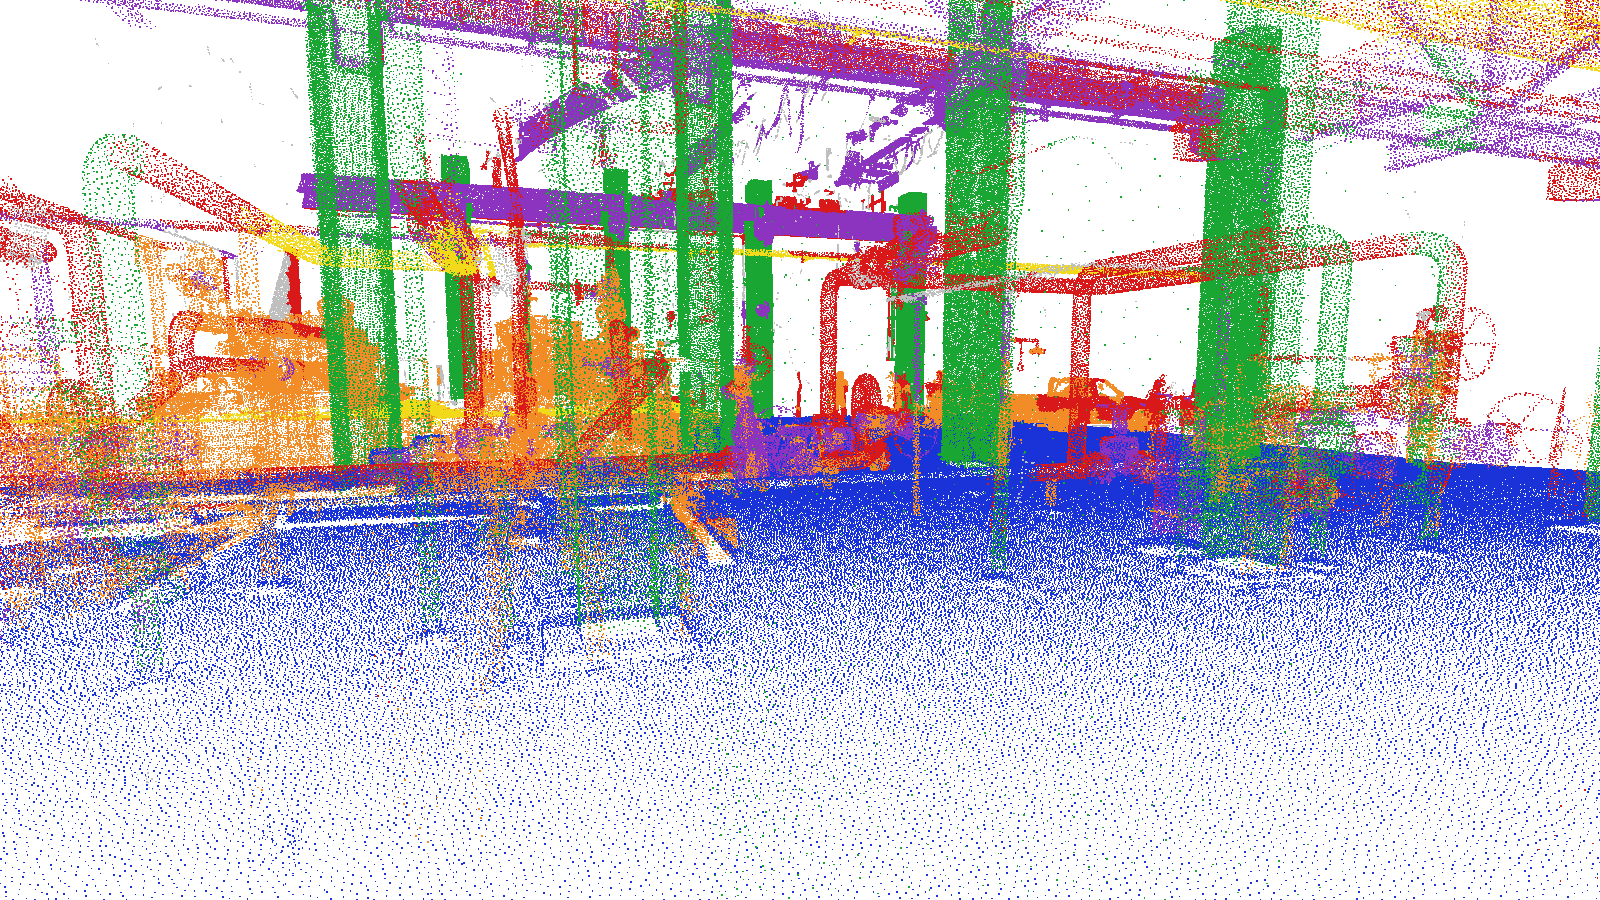

planta


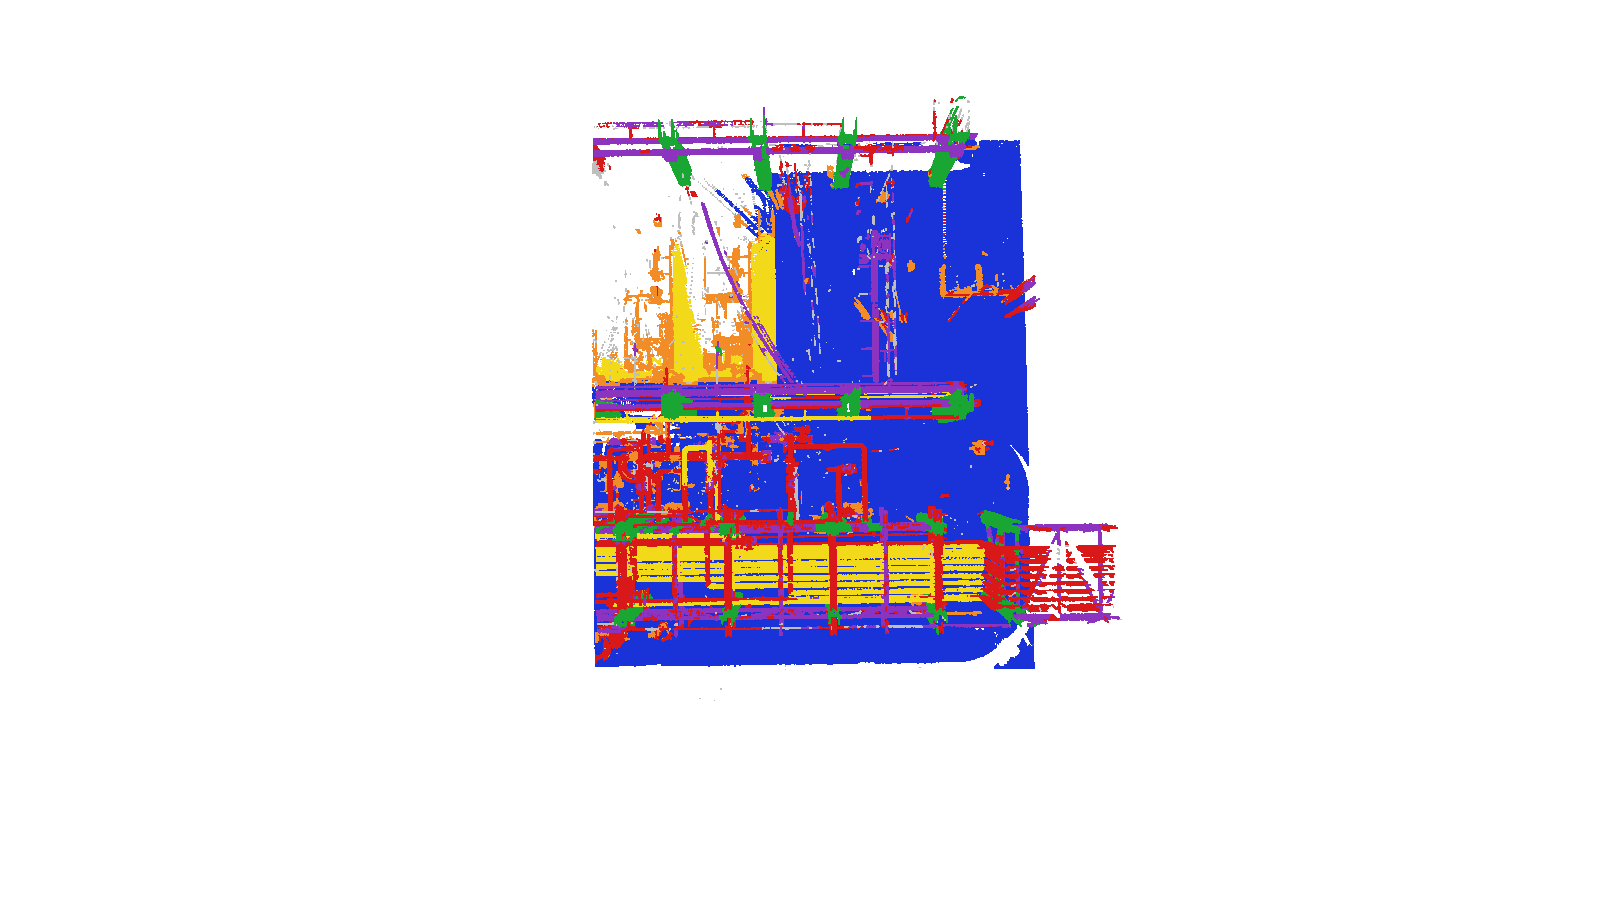

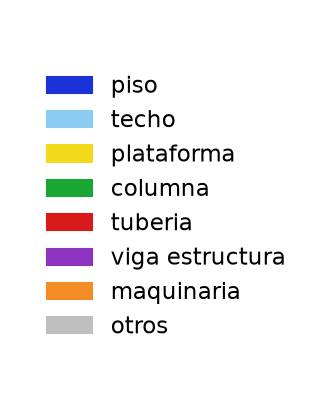

In [19]:
final_colors = colors_from_classes(full_classes)
views = [("aerea", None), ("aerea_opuesta", None), ("lateral", None),
         ("interior_nave", 7.0), ("planta", 7.0)]
for view, hide in views:
    render_view(full.points, final_colors, FIG / f"20_vista_{view}.png", view,
                point_size=1.5, hide_above=hide)
plot_legend({c: n for c, n in C.CLASS_NAMES.items()}, FIG / "21_leyenda.png")
for view, _ in views:
    print(view)
    display(Image(filename=str(FIG / f"20_vista_{view}.png"), width=900))
display(Image(filename=str(FIG / "21_leyenda.png")))

## 11. Limitaciones

- **Personas y vehículos** no se detectan como clase propia: no se encontraron
  ejemplos claros en la nube y su forma se confunde con la maquinaria.
- **Reglas dependientes de la escena**: "material claro = tubería" vale para
  esta fábrica, no necesariamente para otra.
- **Color poco separable**: silhouette ≈ 0.35; el resultado de tuberías y
  maquinaria depende de k (ver estabilidad).
- **Rack de tuberías** de la estructura abierta: algunos soportes claros quedan
  como tubería.